In [3]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
import pandahouse

# A/A-тест: проверка сплитования

**Задача:** проверить, как часто t-тест обнаруживает статистически значимые различия между группами, для которых не предполагается продуктового изменения.

**Данные:** пользовательский CTR групп 2 и 3 за 22–28 мая 2026 года. Этот A/A-тест не следует путать с последующим A/B-тестом групп 1 и 2.

**Метод:** 10 000 повторных случайных выборок по 500 пользователей из каждой группы без повторов внутри выборки, t-тест Уэлча, уровень значимости 5%.

**Сохранённый результат:** доля p-value ниже 0,05 равна **4,78%**. Это близко к ожидаемым 5% и не указывает на явное завышение частоты ложноположительных результатов в данной проверке. Само по себе это не гарантирует корректность рандомизации по всем показателям.

Параметры доступа к учебной базе удалены; оригинальные статистические результаты и графики сохранены.


In [4]:
# Исходная учебная база недоступна. Для повторного запуска нужны свои параметры подключения.
# Секреты не хранятся в ноутбуке и не публикуются в репозитории.
import os

required = ('CLICKHOUSE_HOST', 'CLICKHOUSE_USER', 'CLICKHOUSE_PASSWORD')
missing = [key for key in required if not os.getenv(key)]
if missing:
    raise RuntimeError('Нет переменных окружения: ' + ', '.join(missing))

connection = {
    'host': os.environ['CLICKHOUSE_HOST'],
    'user': os.environ['CLICKHOUSE_USER'],
    'password': os.environ['CLICKHOUSE_PASSWORD'],
    'database': os.getenv('CLICKHOUSE_DATABASE', 'simulator_20260620')
}


In [5]:
q = """
SELECT exp_group, 
       user_id,
       sum(action = 'like') as likes,
       sum(action = 'view') as views,
       likes/views as ctr
FROM {db}.feed_actions 
WHERE toDate(time) between '2026-05-22' and '2026-05-28'
  and exp_group in (2,3)
GROUP BY exp_group, user_id
"""

In [6]:
df = pandahouse.read_clickhouse(q, connection=connection)
df

In [8]:
# Один АА тест
stats.ttest_ind(df[df.exp_group == 2].ctr,
                df[df.exp_group == 3].ctr,
                equal_var=False)

Ttest_indResult(statistic=0.6617303509169987, pvalue=0.508153138292614)

In [10]:
# Цикл 10 000 раз без возвращений

n = 10000
p_values = []

In [11]:
# Извлекаем CTR нужных нам групп
ctr_group2 = df[df.exp_group == 2]['ctr']
ctr_group3 = df[df.exp_group == 3]['ctr']
for i in range(n):
    sample2 = ctr_group2.sample(500, replace=False)
    sample3 = ctr_group3.sample(500, replace=False)

    t_stat, p_value = stats.ttest_ind(sample2, sample3, equal_var=False)
    
    p_values.append(p_value)

In [13]:
# Доля p-value, оказавшихся ниже порога значимости в 0.05

np.mean(np.array(p_values) < 0.05)

0.0478

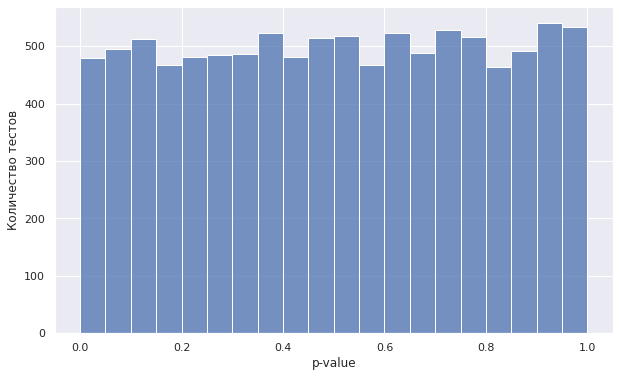

In [14]:
# Построим гистограмму распределения
sns.set(rc={'figure.figsize':(10, 6)})
sns.histplot(p_values, bins=20, kde=False)
plt.xlabel('p-value')
plt.ylabel('Количество тестов')
plt.show()